In [1]:
pip install tensorflow numpy opencv-python matplotlib



   ---------------------------------------- 0.0/390.3 MB ? eta -:--:--
   ---------------------------------------- 0.5/390.3 MB 4.2 MB/s eta 0:01:33
   ---------------------------------------- 1.3/390.3 MB 3.7 MB/s eta 0:01:45
   ---------------------------------------- 1.8/390.3 MB 3.5 MB/s eta 0:01:52
   ---------------------------------------- 2.6/390.3 MB 3.5 MB/s eta 0:01:51
   ---------------------------------------- 3.4/390.3 MB 3.6 MB/s eta 0:01:48
   ---------------------------------------- 4.2/390.3 MB 3.6 MB/s eta 0:01:48
    --------------------------------------- 5.0/390.3 MB 3.6 MB/s eta 0:01:48
    --------------------------------------- 5.8/390.3 MB 3.6 MB/s eta 0:01:46
    --------------------------------------- 6.8/390.3 MB 3.8 MB/s eta 0:01:42
    --------------------------------------- 7.9/390.3 MB 3.9 MB/s eta 0:01:38
    --------------------------------------- 8.9/390.3 MB 4.0 MB/s eta 0:01:36
    --------------------------------------- 9.7/390.3 MB 3.9 MB/s eta 

Found 674 images belonging to 2 classes.
Found 168 images belonging to 2 classes.


c:\Users\hp\anaconda3\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)
c:\Users\hp\anaconda3\Lib\site-packages\keras\src\trainers\data_adapters\py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


Epoch 1/10
22/22 ━━━━━━━━━━━━━━━━━━━━ 23s 864ms/step - accuracy: 0.5535 - loss: 1.9365 - val_accuracy: 0.7202 - val_loss: 0.5610
Epoch 2/10
22/22 ━━━━━━━━━━━━━━━━━━━━ 11s 504ms/step - accuracy: 0.8642 - loss: 0.3066 - val_accuracy: 0.9583 - val_loss: 0.1626
Epoch 3/10
22/22 ━━━━━━━━━━━━━━━━━━━━ 13s 572ms/step - accuracy: 0.9523 - loss: 0.1307 - val_accuracy: 0.9643 - val_loss: 0.1197
Epoch 4/10
22/22 ━━━━━━━━━━━━━━━━━━━━ 10s 475ms/step - accuracy: 0.9723 - loss: 0.0811 - val_accuracy: 0.9345 - val_loss: 0.1789
Epoch 5/10
22/22 ━━━━━━━━━━━━━━━━━━━━ 11s 477ms/step - accuracy: 0.9617 - loss: 0.1163 - val_accuracy: 0.9524 - val_loss: 0.1883
Epoch 6/10
22/22 ━━━━━━━━━━━━━━━━━━━━ 10s 445ms/step - accuracy: 0.9839 - loss: 0.0660 - val_accuracy: 0.9524 - val_loss: 0.1265
Epoch 7/10
22/22 ━━━━━━━━━━━━━━━━━━━━ 10s 458ms/step - accuracy: 0.9859 - loss: 0.0405 - val_accuracy: 0.9702 - val_loss: 0.0840
Epoch 8/10
22/22 ━━━━━━━━━━━━━━━━━━━━ 10s 449ms/step - accuracy: 0.9975 - loss: 0.0211 - val_accu

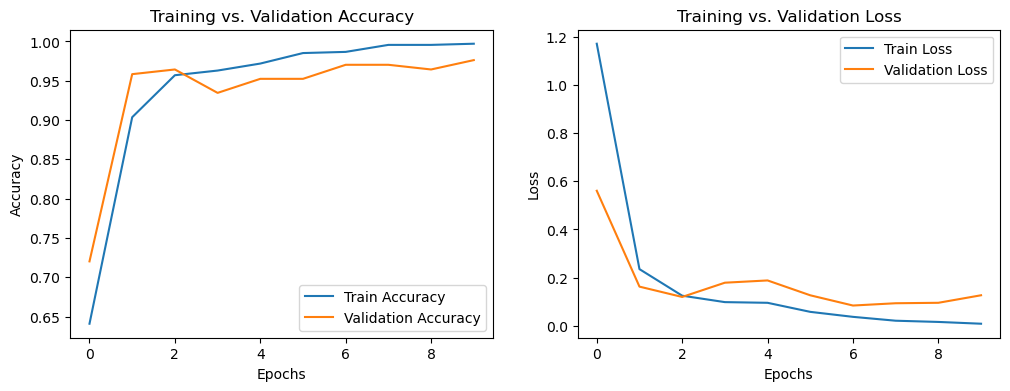

In [5]:
import os
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout
from tensorflow.keras.models import load_model
import cv2

# dataset path
data_dir = "../dataset/train/"
    
# Image Data Augmentation
data_gen = ImageDataGenerator(
    rescale=1.0/255.0,
    validation_split=0.2
)

# Load Train and Validation Data
train_data = data_gen.flow_from_directory(
    data_dir,
    target_size=(128, 128),
    batch_size=32,
    class_mode='categorical',
    subset='training'
)
val_data = data_gen.flow_from_directory(
    data_dir,
    target_size=(128, 128),
    batch_size=32,
    class_mode='categorical',
    subset='validation'
)

# CNN Model
model = Sequential([
    Conv2D(32, (3,3), activation='relu', input_shape=(128, 128, 3)),
    MaxPooling2D(2,2),
    Conv2D(64, (3,3), activation='relu'),
    MaxPooling2D(2,2),
    Flatten(),
    Dense(128, activation='relu'),
    Dropout(0.5),
    Dense(2, activation='softmax')
])

# Compile Model
model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])

# Train Model
history = model.fit(train_data, validation_data=val_data, epochs=10)

# Save Model
model.save("../face_mask_model.h5")

import matplotlib.pyplot as plt  

plt.figure(figsize=(12, 4))

# Plot Accuracy
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.title('Training vs. Validation Accuracy')
plt.legend()

# Plot Loss
plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.title('Training vs. Validation Loss')
plt.legend()

plt.show()


In [1]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report
import numpy as np

# Example: Assuming you have the true labels and predicted labels from the model
y_true = np.array([0, 1, 1, 0, 1, 0, 1, 0, 1, 0])  # Actual labels (0: Mask, 1: No Mask)
y_pred = np.array([0, 1, 1, 0, 0, 0, 1, 0, 1, 1])  # Predicted labels by model

# Compute Evaluation Metrics
accuracy = accuracy_score(y_true, y_pred) * 100
precision = precision_score(y_true, y_pred) * 100
recall = recall_score(y_true, y_pred) * 100
f1 = f1_score(y_true, y_pred) * 100

# Print results
print(f"Accuracy: {accuracy:.2f}%")
print(f"Precision: {precision:.2f}%")
print(f"Recall: {recall:.2f}%")
print(f"F1-score: {f1:.2f}%")

# Detailed Report
print("\nClassification Report:\n", classification_report(y_true, y_pred))


Accuracy: 80.00%
Precision: 80.00%
Recall: 80.00%
F1-score: 80.00%

Classification Report:
               precision    recall  f1-score   support

           0       0.80      0.80      0.80         5
           1       0.80      0.80      0.80         5

    accuracy                           0.80        10
   macro avg       0.80      0.80      0.80        10
weighted avg       0.80      0.80      0.80        10



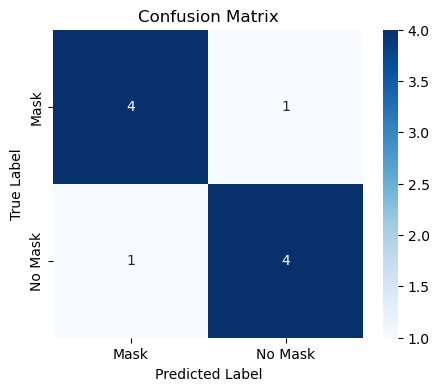

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# Example: Replace these with actual labels and predictions from your model
y_true = np.array([0, 1, 1, 0, 1, 0, 1, 0, 1, 0])  # True labels
y_pred = np.array([0, 1, 1, 0, 0, 0, 1, 0, 1, 1])  # Model predictions

# Compute confusion matrix
cm = confusion_matrix(y_true, y_pred)

# Plot confusion matrix
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=["Mask", "No Mask"], yticklabels=["Mask", "No Mask"])
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("Confusion Matrix")
plt.show()


NameError: name 'history' is not defined

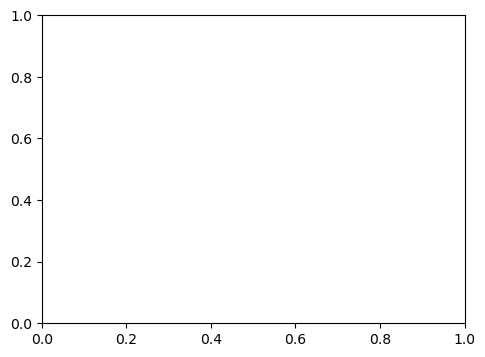

In [3]:
# Assuming `history` is the object returned from model.fit()
plt.figure(figsize=(12, 4))

# Plot Accuracy
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.title('Training vs. Validation Accuracy')
plt.legend()

# Plot Loss
plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.title('Training vs. Validation Loss')
plt.legend()

plt.show()
